# 🧹 Data Cleaning & Preprocessing Pipeline
### Data Science Project — Task 2

---

**Objective:** Take a deliberately messy synthetic dataset and transform it into a clean,
analysis-ready version through a structured, documented pipeline.

| Phase | Steps Covered |
|---|---|
| **Import** | Load raw data, initial inspection |
| **Assessment** | Audit missing values, types, duplicates |
| **Cleaning** | Handle nulls, fix types, remove duplicates |
| **Outliers** | Z-score + IQR detection and treatment |
| **Transformation** | Scaling, normalization, encoding |
| **Feature Engineering** | Derive new meaningful features |
| **Validation** | Before/after comparison, quality report |
| **Visualization** | Distribution comparisons, heatmaps |

---
## 📦 Step 1 — Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, LabelEncoder, OneHotEncoder
)
from sklearn.impute import SimpleImputer
import warnings
warnings.filterwarnings('ignore')

# ── Style ────────────────────────────────────────────────────────────
sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams.update({'figure.dpi': 120})
BLUE, RED, GREEN, ORANGE = '#4C72B0', '#C44E52', '#55A868', '#DD8452'

pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', '{:.3f}'.format)
print('✅ All libraries loaded')

✅ All libraries loaded


---
## 🏗️ Step 2 — Generate Messy Dataset

> We simulate a realistic **customer sales dataset** with intentionally injected data quality issues: missing values, duplicates, typos in categories, wrong data types, impossible values, and outliers.

In [2]:
np.random.seed(42)
n = 500

# ── Base clean data ──────────────────────────────────────────────────
ages         = np.random.randint(18, 70, n).astype(float)
incomes      = np.random.normal(55000, 15000, n)
spend        = incomes * np.random.uniform(0.05, 0.35, n) + np.random.normal(0, 500, n)
satisfaction = np.random.choice([1,2,3,4,5], n)
genders      = np.random.choice(['Male','Female','Other'], n, p=[0.48,0.48,0.04])
regions      = np.random.choice(['North','South','East','West'], n)
tenure_yrs   = np.random.exponential(3, n)
purchases    = np.random.poisson(12, n).astype(float)

df_raw = pd.DataFrame({
    'customer_id' : [f'CUST{str(i).zfill(4)}' for i in range(1, n+1)],
    'age'         : ages,
    'gender'      : genders,
    'region'      : regions,
    'annual_income': incomes,
    'annual_spend' : spend,
    'satisfaction' : satisfaction,
    'tenure_years' : tenure_yrs,
    'num_purchases': purchases,
})

# ── Inject data quality issues ───────────────────────────────────────
rng = np.random.default_rng(42)

# 1. Missing values (~10% across several columns)
for col, pct in [('age',0.08),('annual_income',0.10),('gender',0.06),
                 ('satisfaction',0.07),('tenure_years',0.05)]:
    idx = rng.choice(n, int(n*pct), replace=False)
    df_raw.loc[idx, col] = np.nan

# 2. Duplicate rows
dup_idx = rng.choice(n, 15, replace=False)
df_raw = pd.concat([df_raw, df_raw.iloc[dup_idx]], ignore_index=True)

# 3. Typos / inconsistent categories
typo_idx = rng.choice(n, 30, replace=False)
df_raw.loc[typo_idx, 'gender'] = rng.choice(
    ['male','FEMALE','M','F','female','MALE'], len(typo_idx))
region_typos = rng.choice(n, 20, replace=False)
df_raw.loc[region_typos, 'region'] = rng.choice(
    ['north','SOUTH','Est','Westt'], len(region_typos))

# 4. Impossible / wrong values
df_raw.loc[rng.choice(n,5,replace=False), 'age']           = rng.choice([-5, 0, 200], 5)
df_raw.loc[rng.choice(n,5,replace=False), 'annual_income'] = rng.choice([-1000, -500], 5)
df_raw.loc[rng.choice(n,5,replace=False), 'satisfaction']  = rng.choice([0, 7, 10], 5)

# 5. Outliers
df_raw.loc[rng.choice(n,6,replace=False), 'annual_income'] = rng.choice([250000,300000,350000],6)
df_raw.loc[rng.choice(n,4,replace=False), 'annual_spend']  = rng.choice([80000,95000],4)

# 6. Wrong data type (income stored as string)
df_raw['annual_income'] = df_raw['annual_income'].astype(str)
# Inject 'N/A' strings as extra missing markers
str_idx = rng.choice(len(df_raw), 10, replace=False)
df_raw.loc[str_idx, 'annual_income'] = 'N/A'

# 7. Shuffle
df_raw = df_raw.sample(frac=1, random_state=42).reset_index(drop=True)

print(f'Raw dataset shape: {df_raw.shape}')
df_raw.head(10)

Raw dataset shape: (515, 9)


,customer_id,age,gender,region,annual_income,annual_spend,satisfaction,tenure_years,num_purchases
0,CUST0305,36.000,Female,South,47685.906638912595,12756.784,NaN,1.309,10.000
1,CUST0500,18.000,Female,East,nan,2878.990,1.000,7.334,15.000
2,CUST0442,32.000,Male,South,64239.034104163955,18474.067,5.000,0.629,14.000
3,CUST0154,43.000,Male,East,64342.748985212485,5640.906,1.000,5.217,13.000
4,CUST0234,49.000,Female,East,nan,3286.808,1.000,2.601,13.000
5,CUST0132,54.000,Female,East,47113.674674788585,4962.937,2.000,4.138,12.000
6,CUST0205,54.000,Male,North,53394.544600681635,12445.165,3.000,6.084,17.000
7,CUST0012,28.000,Female,South,39634.185379985654,2943.762,NaN,4.202,13.000
8,CUST0326,46.000,Female,South,66562.9779083045,7279.177,3.000,1.749,10.000
9,CUST0248,NaN,Male,South,34258.00403553496,9776.815,4.000,2.635,15.000


---
## 🔍 Step 3 — Initial Data Assessment

In [3]:
print('═' * 55)
print('  DATA TYPES & NON-NULL COUNTS')
print('═' * 55)
df_raw.info()

═══════════════════════════════════════════════════════
  DATA TYPES & NON-NULL COUNTS
═══════════════════════════════════════════════════════
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 515 entries, 0 to 514
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   customer_id    515 non-null    object 
 1   age            474 non-null    float64
 2   gender         491 non-null    object 
 3   region         515 non-null    object 
 4   annual_income  515 non-null    object 
 5   annual_spend   515 non-null    float64
 6   satisfaction   478 non-null    float64
 7   tenure_years   488 non-null    float64
 8   num_purchases  515 non-null    float64
dtypes: float64(5), object(4)
memory usage: 36.3+ KB


In [4]:
# ── Missing value audit ──────────────────────────────────────────────
def missing_report(df, label='Dataset'):
    miss = df.isnull().sum()
    pct  = (miss / len(df) * 100).round(2)
    report = pd.DataFrame({'Missing Count': miss, 'Missing %': pct})
    report = report[report['Missing Count'] > 0].sort_values('Missing %', ascending=False)
    print(f'\n📋 Missing Value Report — {label}')
    print(f'   Total rows: {len(df)} | Affected columns: {len(report)}')
    return report

missing_report(df_raw, 'RAW')


📋 Missing Value Report — RAW
   Total rows: 515 | Affected columns: 4


,Missing Count,Missing %
age,41,7.960
satisfaction,37,7.180
tenure_years,27,5.240
gender,24,4.660


In [5]:
# ── Duplicate audit ──────────────────────────────────────────────────
dup_count = df_raw.duplicated().sum()
dup_pct   = dup_count / len(df_raw) * 100
print(f'🔁 Duplicate rows: {dup_count}  ({dup_pct:.1f}% of dataset)')
if dup_count > 0:
    print('   Sample duplicates:')
    display(df_raw[df_raw.duplicated(keep=False)].sort_values('customer_id').head(6))

🔁 Duplicate rows: 14  (2.7% of dataset)
   Sample duplicates:


,customer_id,age,gender,region,annual_income,annual_spend,satisfaction,tenure_years,num_purchases
70,CUST0012,28.000,Female,South,39634.185379985654,2943.762,NaN,4.202,13.000
7,CUST0012,28.000,Female,South,39634.185379985654,2943.762,NaN,4.202,13.000
126,CUST0045,NaN,Female,East,nan,8022.256,NaN,0.409,9.000
330,CUST0045,NaN,Female,East,nan,8022.256,NaN,0.409,9.000
38,CUST0074,46.000,Female,South,36787.17080818402,5104.248,4.000,2.813,11.000
182,CUST0074,46.000,Female,South,36787.17080818402,5104.248,4.000,2.813,11.000


In [6]:
# ── Categorical value audit ──────────────────────────────────────────
print('🔤 Unique values in categorical columns:\n')
for col in ['gender', 'region']:
    vals = df_raw[col].dropna().unique()
    print(f'  {col}: {sorted(vals)}')

🔤 Unique values in categorical columns:

  gender: ['F', 'FEMALE', 'Female', 'M', 'MALE', 'Male', 'Other', 'female', 'male']
  region: ['East', 'Est', 'North', 'SOUTH', 'South', 'West', 'Westt', 'north']


In [7]:
# ── Value range audit ────────────────────────────────────────────────
print('📏 Numeric range check (raw):\n')
range_checks = {
    'age'         : (18, 99),
    'satisfaction': (1, 5),
    'tenure_years': (0, 50),
    'num_purchases': (0, 200),
}
for col, (lo, hi) in range_checks.items():
    series = pd.to_numeric(df_raw[col], errors='coerce')
    bad = ((series < lo) | (series > hi)).sum()
    print(f'  {col:<18} valid range [{lo}, {hi}]  → {bad} invalid value(s)')

📏 Numeric range check (raw):

  age                valid range [18, 99]  → 5 invalid value(s)
  satisfaction       valid range [1, 5]  → 5 invalid value(s)
  tenure_years       valid range [0, 50]  → 0 invalid value(s)
  num_purchases      valid range [0, 200]  → 0 invalid value(s)


---
## 🧽 Step 4 — Data Cleaning

### 4a — Fix Data Types

In [8]:
df = df_raw.copy()

# Replace string 'N/A', 'nan', 'None' with actual NaN before numeric conversion
df['annual_income'] = df['annual_income'].replace(
    ['N/A', 'nan', 'None', 'null', ''], np.nan)

# Convert to numeric (coerce remaining non-numeric to NaN)
df['annual_income'] = pd.to_numeric(df['annual_income'], errors='coerce')
df['age']           = pd.to_numeric(df['age'],           errors='coerce')

print('✅ Data types after fix:')
print(df.dtypes)

✅ Data types after fix:
customer_id       object
age              float64
gender            object
region            object
annual_income    float64
annual_spend     float64
satisfaction     float64
tenure_years     float64
num_purchases    float64
dtype: object


### 4b — Remove Duplicates

In [9]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
after = len(df)
print(f'✅ Removed {before - after} duplicate rows  ({before} → {after} rows)')

✅ Removed 14 duplicate rows  (515 → 501 rows)


### 4c — Fix Invalid / Impossible Values

In [10]:
# Age: valid range 18–99  → set invalid to NaN (will impute later)
invalid_age = (df['age'] < 18) | (df['age'] > 99)
df.loc[invalid_age, 'age'] = np.nan
print(f'  age       — {invalid_age.sum()} invalid values set to NaN')

# Income: cannot be negative → set to NaN
invalid_inc = df['annual_income'] < 0
df.loc[invalid_inc, 'annual_income'] = np.nan
print(f'  income    — {invalid_inc.sum()} negative values set to NaN')

# Satisfaction: valid range 1–5
invalid_sat = ~df['satisfaction'].isin([1, 2, 3, 4, 5])
df.loc[invalid_sat, 'satisfaction'] = np.nan
print(f'  satisfaction — {invalid_sat.sum()} out-of-range values set to NaN')

print('\n✅ Invalid values replaced with NaN for imputation')

  age       — 5 invalid values set to NaN
  income    — 5 negative values set to NaN
  satisfaction — 40 out-of-range values set to NaN

✅ Invalid values replaced with NaN for imputation


### 4d — Standardise Categorical Values

In [11]:
# ── Gender standardisation ───────────────────────────────────────────
gender_map = {
    'male':'Male','m':'Male','MALE':'Male',
    'female':'Female','f':'Female','FEMALE':'Female','F':'Female','M':'Male'
}
df['gender'] = df['gender'].map(
    lambda x: gender_map.get(str(x).strip(), x) if pd.notna(x) else x
)

# ── Region standardisation ───────────────────────────────────────────
region_map = {
    'north':'North','NORTH':'North',
    'south':'South','SOUTH':'South',
    'east' :'East' ,'EAST' :'East','Est':'East',
    'west' :'West' ,'WEST' :'West','Westt':'West'
}
df['region'] = df['region'].map(
    lambda x: region_map.get(str(x).strip(), x) if pd.notna(x) else x
)

print('✅ After standardisation:')
print(f'  gender  unique: {sorted(df["gender"].dropna().unique())}')
print(f'  region  unique: {sorted(df["region"].dropna().unique())}')

✅ After standardisation:
  gender  unique: ['Female', 'Male', 'Other']
  region  unique: ['East', 'North', 'South', 'West']


---
## 🩹 Step 5 — Missing Value Imputation

> **Strategy:**
> - Numeric columns: median imputation (robust to outliers)
> - Categorical columns: mode imputation
> - High-missing columns (>30%): evaluate for dropping

In [12]:
print('Missing values BEFORE imputation:')
print(df.isnull().sum()[df.isnull().sum() > 0])

# ── Numeric: median imputation ───────────────────────────────────────
num_cols = ['age', 'annual_income', 'tenure_years']
num_imputer = SimpleImputer(strategy='median')
df[num_cols] = num_imputer.fit_transform(df[num_cols])

# ── Categorical: mode imputation ─────────────────────────────────────
cat_cols = ['gender', 'satisfaction']
for col in cat_cols:
    mode_val = df[col].mode()[0]
    df[col].fillna(mode_val, inplace=True)

print('\nMissing values AFTER imputation:')
remaining = df.isnull().sum().sum()
print(f'  Total missing: {remaining}')
if remaining == 0:
    print('  ✅ Dataset is now complete — no missing values')

Missing values BEFORE imputation:
age              45
gender           24
annual_income    62
satisfaction     40
tenure_years     26
dtype: int64

Missing values AFTER imputation:
  Total missing: 0
  ✅ Dataset is now complete — no missing values


---
## 🎯 Step 6 — Outlier Detection & Treatment

In [13]:
outlier_cols = ['annual_income', 'annual_spend', 'age', 'tenure_years']

print('Outlier Detection Summary\n')
print(f'{"Column":<20} {"Z>3":>8} {"IQR":>8}  {"Min":>10} {"Max":>10}')
print('-'*60)

outlier_report = {}
for col in outlier_cols:
    # Z-score method
    z = np.abs(stats.zscore(df[col].dropna()))
    z_count = (z > 3).sum()
    # IQR method
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    iqr_count = ((df[col] < Q1-1.5*IQR) | (df[col] > Q3+1.5*IQR)).sum()
    outlier_report[col] = {'Q1':Q1,'Q3':Q3,'IQR':IQR,'lower':Q1-1.5*IQR,'upper':Q3+1.5*IQR}
    print(f'{col:<20} {z_count:>8} {iqr_count:>8}  {df[col].min():>10.1f} {df[col].max():>10.1f}')

Outlier Detection Summary

Column                    Z>3      IQR         Min        Max
------------------------------------------------------------
annual_income               6       12      6381.0   350000.0
annual_spend                4        5      1510.7    95000.0
age                         0        0        18.0       69.0
tenure_years               12       26         0.0       16.9


In [14]:
# ── Treatment: Winsorise (cap) outliers to IQR fences ───────────────
# (Preferred over deletion — preserves data volume)
df_clean = df.copy()

for col in ['annual_income', 'annual_spend']:
    lower = outlier_report[col]['lower']
    upper = outlier_report[col]['upper']
    before_min, before_max = df_clean[col].min(), df_clean[col].max()
    df_clean[col] = df_clean[col].clip(lower=lower, upper=upper)
    print(f'{col}:')
    print(f'  Before: [{before_min:.0f}, {before_max:.0f}]')
    print(f'  After : [{df_clean[col].min():.0f}, {df_clean[col].max():.0f}]  (winsorised)\n')

print('✅ Outliers capped using IQR winsorisation')

annual_income:
  Before: [6381, 350000]
  After : [19551, 90107]  (winsorised)

annual_spend:
  Before: [1511, 95000]
  After : [1511, 28997]  (winsorised)

✅ Outliers capped using IQR winsorisation


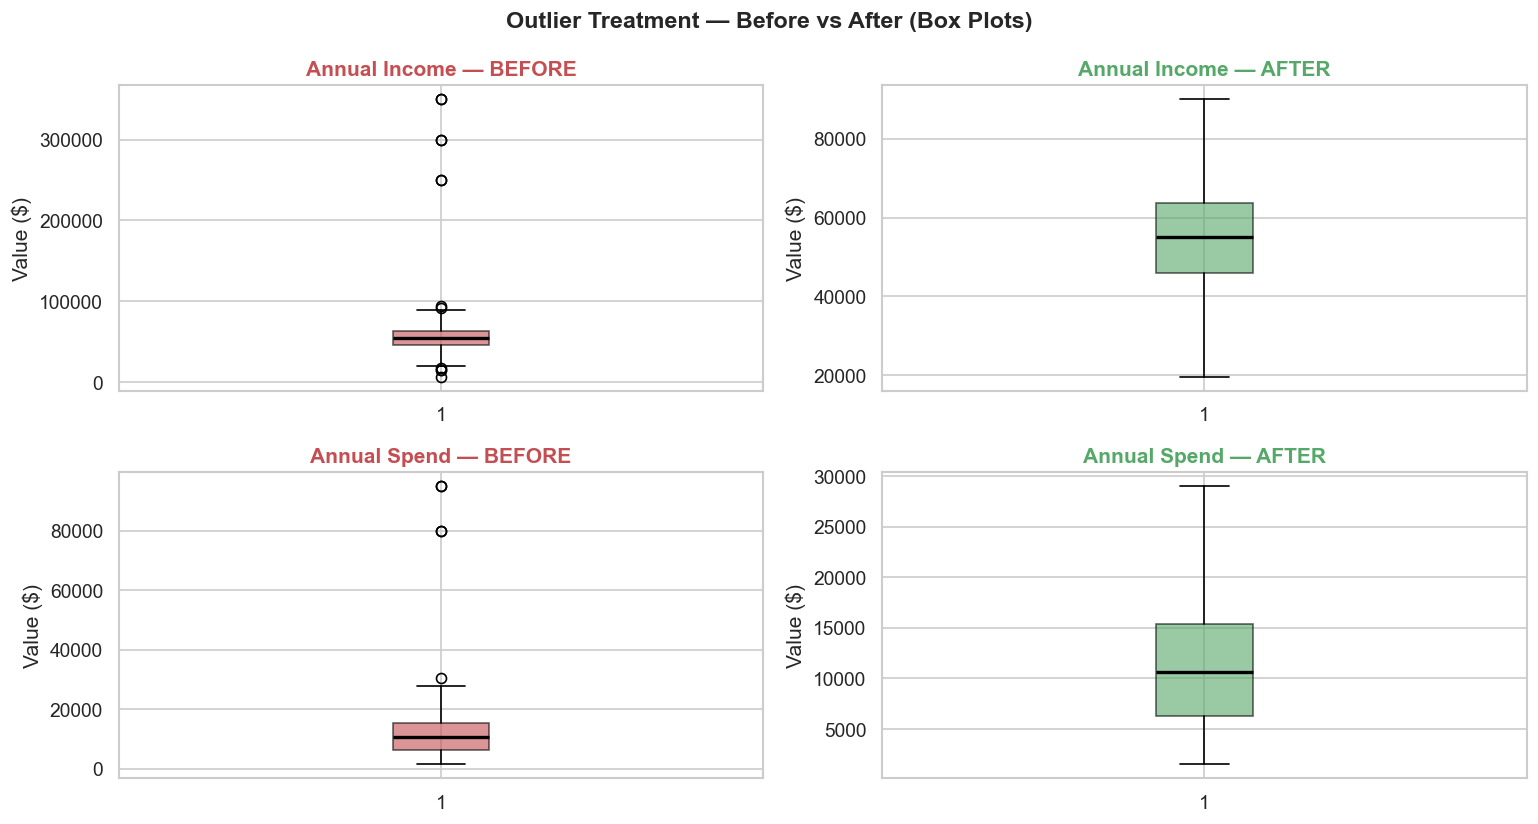

In [15]:
# ── Before / After Outlier Visualisation ────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
fig.suptitle('Outlier Treatment — Before vs After (Box Plots)',
             fontsize=14, fontweight='bold')

pairs = [('annual_income','Annual Income'),('annual_spend','Annual Spend')]
for row, (col, label) in enumerate(pairs):
    # Before
    axes[row][0].boxplot(df[col].dropna(), patch_artist=True,
                         boxprops=dict(facecolor=RED, alpha=0.6),
                         medianprops=dict(color='black',lw=2))
    axes[row][0].set_title(f'{label} — BEFORE', fontweight='bold', color=RED)
    axes[row][0].set_ylabel('Value ($)')
    # After
    axes[row][1].boxplot(df_clean[col].dropna(), patch_artist=True,
                         boxprops=dict(facecolor=GREEN, alpha=0.6),
                         medianprops=dict(color='black',lw=2))
    axes[row][1].set_title(f'{label} — AFTER', fontweight='bold', color=GREEN)
    axes[row][1].set_ylabel('Value ($)')

plt.tight_layout()
plt.show()

---
## ⚙️ Step 7 — Feature Engineering

In [16]:
df_feat = df_clean.copy()

# 1. Spend Rate: annual spend as % of income
df_feat['spend_rate'] = (df_feat['annual_spend'] / df_feat['annual_income'] * 100).round(2)

# 2. Income Band: bin income into labeled groups
df_feat['income_band'] = pd.cut(
    df_feat['annual_income'],
    bins=[0, 30000, 50000, 75000, 150000],
    labels=['Low', 'Medium', 'High', 'Very High']
)

# 3. Age Group
df_feat['age_group'] = pd.cut(
    df_feat['age'],
    bins=[17, 25, 35, 50, 99],
    labels=['18-25', '26-35', '36-50', '51+']
)

# 4. Avg spend per purchase
df_feat['avg_purchase_value'] = (
    df_feat['annual_spend'] / (df_feat['num_purchases'] + 1)
).round(2)

# 5. High value customer flag
spend_75th = df_feat['annual_spend'].quantile(0.75)
df_feat['is_high_value'] = (df_feat['annual_spend'] >= spend_75th).astype(int)

print('✅ New features created:')
new_feats = ['spend_rate','income_band','age_group','avg_purchase_value','is_high_value']
for f in new_feats:
    print(f'  + {f}')

df_feat[new_feats].describe(include='all').T

✅ New features created:
  + spend_rate
  + income_band
  + age_group
  + avg_purchase_value
  + is_high_value


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
spend_rate,501.000,NaN,NaN,NaN,20.519,9.431,3.220,12.240,20.840,28.120,59.320
income_band,501,4,High,290,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age_group,501,4,36-50,194,NaN,NaN,NaN,NaN,NaN,NaN,NaN
avg_purchase_value,501.000,NaN,NaN,NaN,946.061,616.584,133.130,497.160,804.910,1264.670,4206.810
is_high_value,501.000,NaN,NaN,NaN,0.251,0.434,0.000,0.000,0.000,1.000,1.000


---
## 🔢 Step 8 — Data Transformation

### 8a — Encode Categorical Variables

In [17]:
df_enc = df_feat.copy()

# ── Label Encoding: binary/ordinal columns ───────────────────────────
le = LabelEncoder()
df_enc['gender_encoded']   = le.fit_transform(df_enc['gender'].astype(str))
df_enc['income_band_enc']  = df_enc['income_band'].cat.codes  # ordinal
df_enc['age_group_enc']    = df_enc['age_group'].cat.codes    # ordinal

print('Label Encoded columns:')
print(f'  gender → {dict(zip(le.classes_, le.transform(le.classes_)))}')

# ── One-Hot Encoding: nominal column (region) ────────────────────────
df_enc = pd.get_dummies(df_enc, columns=['region'], prefix='region', drop_first=True)

print('\n✅ One-Hot Encoded: region')
region_cols = [c for c in df_enc.columns if c.startswith('region_')]
print(f'  New columns: {region_cols}')

Label Encoded columns:
  gender → {'Female': np.int64(0), 'Male': np.int64(1), 'Other': np.int64(2)}

✅ One-Hot Encoded: region
  New columns: ['region_North', 'region_South', 'region_West']


### 8b — Feature Scaling

> **StandardScaler** — zero mean, unit variance (for models sensitive to scale, e.g. SVM, KNN)  
> **MinMaxScaler** — compress to [0, 1] range (for neural networks, distance-based methods)

In [18]:
scale_cols = ['age', 'annual_income', 'annual_spend',
              'tenure_years', 'num_purchases', 'avg_purchase_value']

# ── StandardScaler ───────────────────────────────────────────────────
ss = StandardScaler()
df_standard = df_enc.copy()
df_standard[scale_cols] = ss.fit_transform(df_enc[scale_cols])

# ── MinMaxScaler ─────────────────────────────────────────────────────
mm = MinMaxScaler()
df_minmax = df_enc.copy()
df_minmax[scale_cols] = mm.fit_transform(df_enc[scale_cols])

print('Scaling comparison for annual_income:\n')
comp = pd.DataFrame({
    'Original'  : df_enc['annual_income'].describe(),
    'StandardScaler': df_standard['annual_income'].describe(),
    'MinMaxScaler'  : df_minmax['annual_income'].describe(),
}).round(4)
print(comp)

Scaling comparison for annual_income:

       Original  StandardScaler  MinMaxScaler
count   501.000         501.000       501.000
mean  55064.171          -0.000         0.503
std   14148.815           1.001         0.201
min   19550.905          -2.513         0.000
25%   46009.375          -0.641         0.375
50%   55153.496           0.006         0.505
75%   63648.354           0.607         0.625
max   90106.824           2.479         1.000


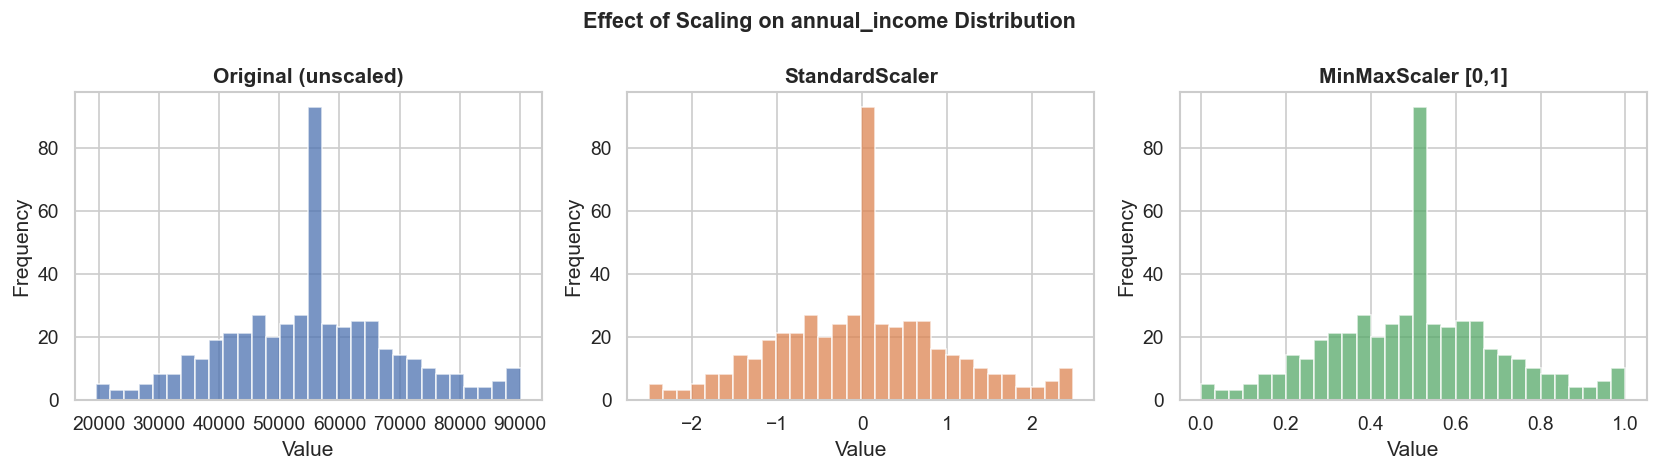

In [19]:
# ── Visualise scaling effect ─────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle('Effect of Scaling on annual_income Distribution',
             fontsize=13, fontweight='bold')

datasets = [
    (df_enc,      'Original (unscaled)', BLUE),
    (df_standard, 'StandardScaler',      ORANGE),
    (df_minmax,   'MinMaxScaler [0,1]',  GREEN),
]
for ax, (data, title, color) in zip(axes, datasets):
    ax.hist(data['annual_income'], bins=30, color=color, alpha=0.75, edgecolor='white')
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Value')
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

---
## 📊 Step 9 — Before vs After Visualisations

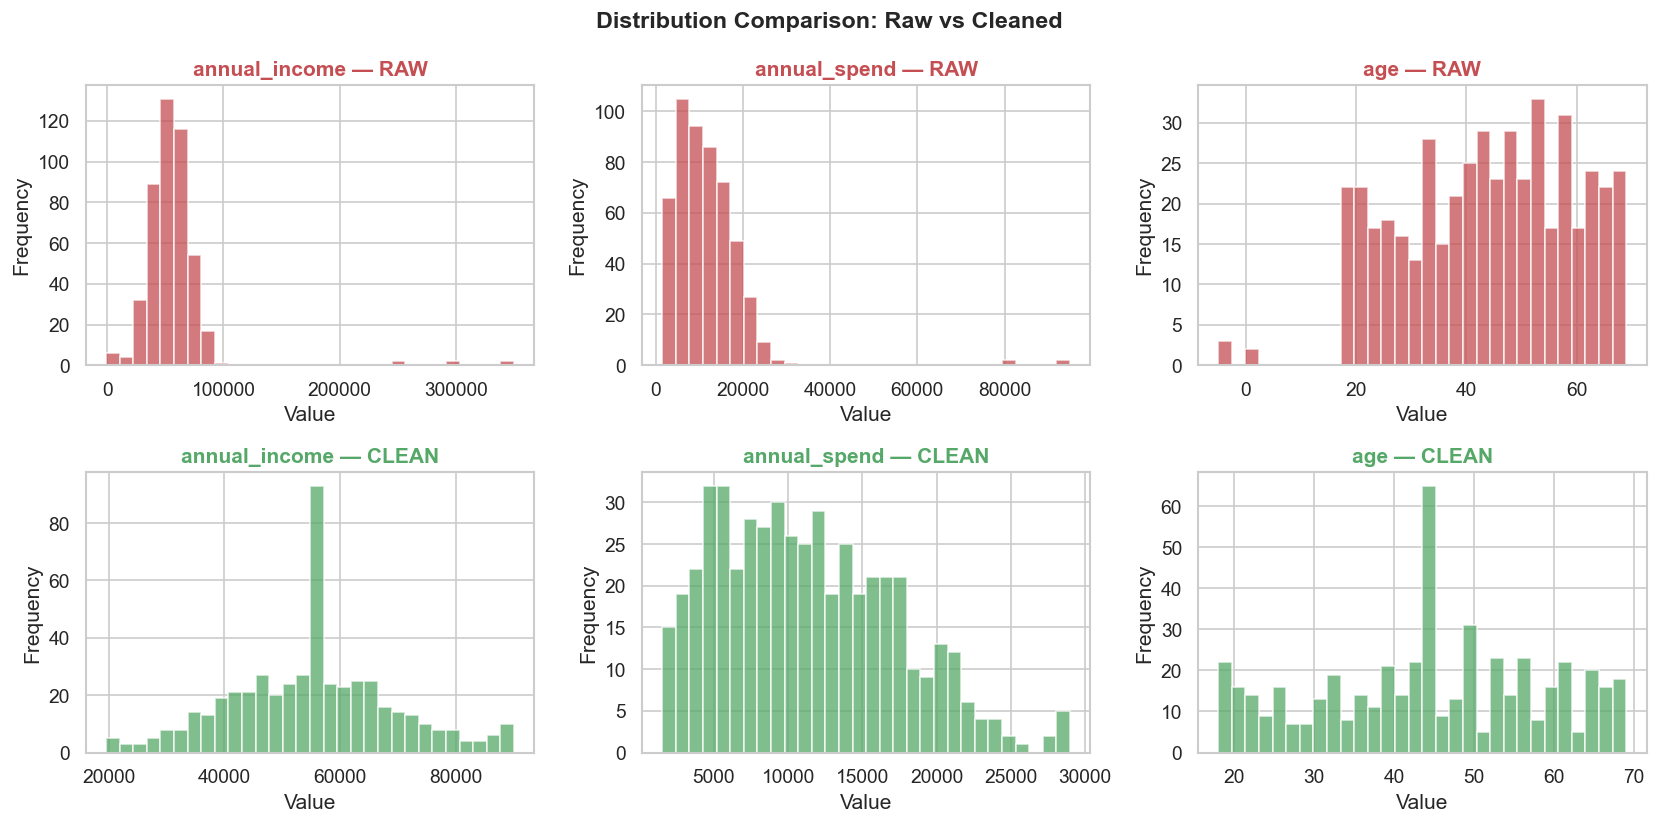

In [20]:
# Distribution comparison: raw vs clean for key numeric columns
compare_cols = ['annual_income', 'annual_spend', 'age']
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
fig.suptitle('Distribution Comparison: Raw vs Cleaned',
             fontsize=14, fontweight='bold')

for col, ax_before, ax_after in zip(
        compare_cols, axes[0], axes[1]):

    raw_vals   = pd.to_numeric(df_raw[col], errors='coerce').dropna()
    clean_vals = df_clean[col].dropna()

    ax_before.hist(raw_vals, bins=30, color=RED, alpha=0.75, edgecolor='white')
    ax_before.set_title(f'{col} — RAW', fontweight='bold', color=RED)
    ax_before.set_xlabel('Value'); ax_before.set_ylabel('Frequency')

    ax_after.hist(clean_vals, bins=30, color=GREEN, alpha=0.75, edgecolor='white')
    ax_after.set_title(f'{col} — CLEAN', fontweight='bold', color=GREEN)
    ax_after.set_xlabel('Value'); ax_after.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

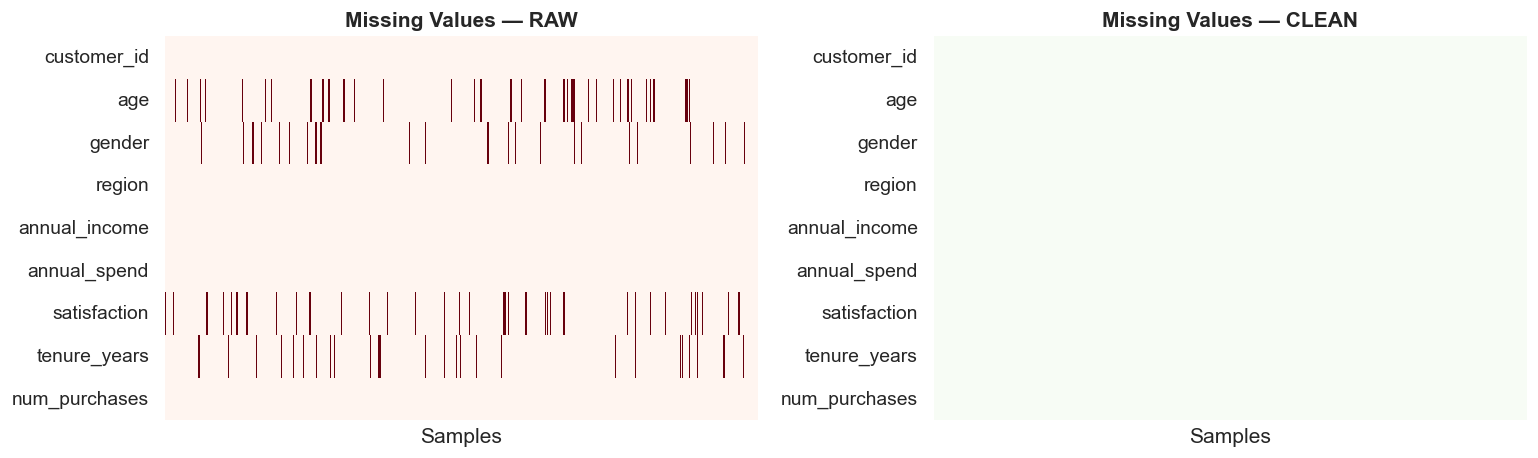

In [21]:
# Missing value heatmap: before & after
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, data, title, cmap in [
    (axes[0], df_raw.isnull(), 'Missing Values — RAW',   'Reds'),
    (axes[1], df_clean.isnull(),'Missing Values — CLEAN', 'Greens'),
]:
    numeric_subset = data.select_dtypes(include='bool')
    sns.heatmap(data.T, ax=ax, cbar=False, yticklabels=True,
                cmap=cmap, linewidths=0, xticklabels=False)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Samples')

plt.tight_layout()
plt.show()

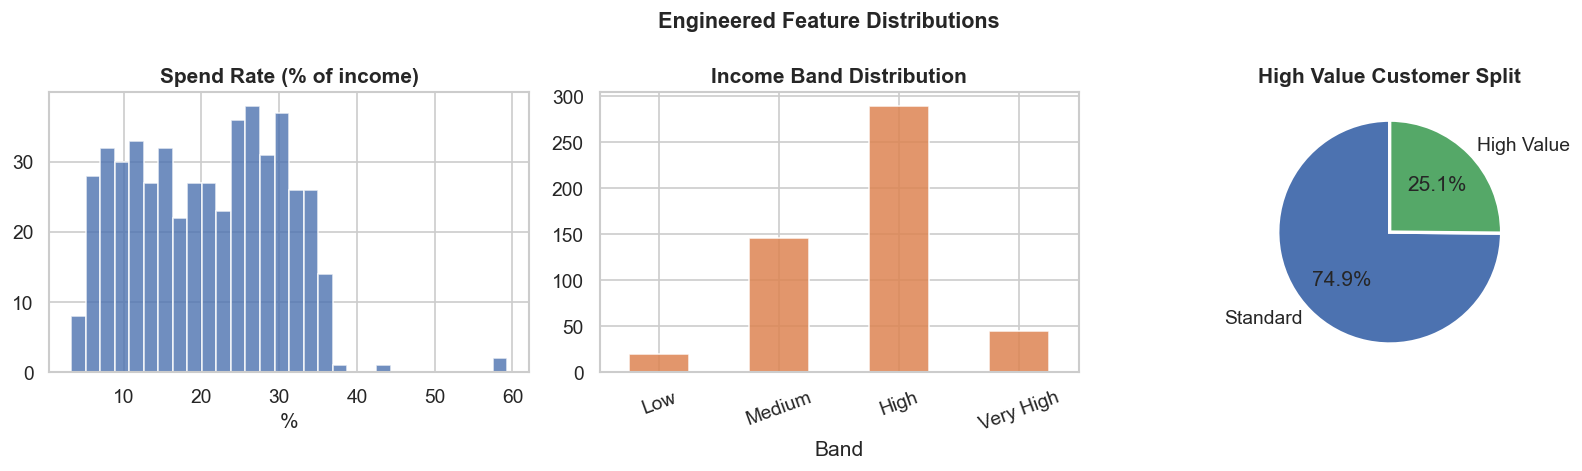

In [22]:
# New feature distributions
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle('Engineered Feature Distributions', fontsize=13, fontweight='bold')

# Spend rate
axes[0].hist(df_feat['spend_rate'].dropna(), bins=30, color=BLUE, alpha=0.8, edgecolor='white')
axes[0].set_title('Spend Rate (% of income)', fontweight='bold')
axes[0].set_xlabel('%')

# Income band
df_feat['income_band'].value_counts().sort_index().plot(
    kind='bar', ax=axes[1], color=ORANGE, alpha=0.85, edgecolor='white')
axes[1].set_title('Income Band Distribution', fontweight='bold')
axes[1].set_xlabel('Band'); axes[1].tick_params(axis='x', rotation=20)

# High value flag
hv = df_feat['is_high_value'].value_counts()
axes[2].pie(hv, labels=['Standard','High Value'], colors=[BLUE, GREEN],
            autopct='%1.1f%%', startangle=90,
            wedgeprops=dict(edgecolor='white',linewidth=2))
axes[2].set_title('High Value Customer Split', fontweight='bold')

plt.tight_layout()
plt.show()

---
## ✅ Step 10 — Data Validation & Quality Report

In [23]:
print('=' * 60)
print('         FINAL DATA QUALITY VALIDATION REPORT')
print('=' * 60)

checks = [
    ('Missing values',   df_clean.isnull().sum().sum() == 0),
    ('Duplicate rows',   df_clean.duplicated().sum() == 0),
    ('Age range [18-99]',df_clean['age'].between(17, 100).all()),
    ('Income > 0',       (df_clean['annual_income'] > 0).all()),
    ('Satisfaction [1-5]', df_clean['satisfaction'].isin([1,2,3,4,5]).all()),
    ('Gender standardised', df_clean['gender'].isin(['Male','Female','Other']).all()),
    ('Region standardised', df_clean['region'].isin(['North','South','East','West']).all()),
    ('Positive spend',   (df_clean['annual_spend'] > 0).all()),
]

all_pass = True
for label, result in checks:
    icon = '✅' if result else '❌'
    if not result: all_pass = False
    print(f'  {icon}  {label}')

print('\n' + '─'*60)
print(f'  Overall: {"✅ ALL CHECKS PASSED" if all_pass else "❌ ISSUES FOUND"}')
print('─'*60)

         FINAL DATA QUALITY VALIDATION REPORT
  ✅  Missing values
  ✅  Duplicate rows
  ✅  Age range [18-99]
  ✅  Income > 0
  ✅  Satisfaction [1-5]
  ✅  Gender standardised
  ✅  Region standardised
  ✅  Positive spend

────────────────────────────────────────────────────────────
  Overall: ✅ ALL CHECKS PASSED
────────────────────────────────────────────────────────────


In [24]:
# ── Shape and completeness comparison ────────────────────────────────
summary = pd.DataFrame({
    'Metric': [
        'Total Rows', 'Total Columns', 'Missing Values',
        'Duplicate Rows', 'Numeric Columns', 'Categorical Columns'
    ],
    'Raw Dataset': [
        len(df_raw),
        len(df_raw.columns),
        df_raw.isnull().sum().sum(),
        df_raw.duplicated().sum(),
        len(df_raw.select_dtypes('number').columns),
        len(df_raw.select_dtypes('object').columns)
    ],
    'Clean Dataset': [
        len(df_clean),
        len(df_clean.columns),
        df_clean.isnull().sum().sum(),
        df_clean.duplicated().sum(),
        len(df_clean.select_dtypes('number').columns),
        len(df_clean.select_dtypes('object').columns)
    ],
    'Final (Engineered)': [
        len(df_enc),
        len(df_enc.columns),
        df_enc.isnull().sum().sum(),
        df_enc.duplicated().sum(),
        len(df_enc.select_dtypes('number').columns),
        len(df_enc.select_dtypes('object').columns)
    ],
}).set_index('Metric')

print('\n📊 Dataset Evolution Summary:')
summary


📊 Dataset Evolution Summary:


,Raw Dataset,Clean Dataset,Final (Engineered)
Metric,,,
Total Rows,515,501,501
Total Columns,9,9,19
Missing Values,129,0,0
Duplicate Rows,14,0,0
Numeric Columns,5,6,12
Categorical Columns,4,3,2


---
## 💾 Step 11 — Export Clean Dataset

In [25]:
# Save cleaned version (unscaled, encoded, with engineered features)
df_enc.to_csv('cleaned_dataset.csv', index=False)

# Save standardised version (ML-ready)
df_standard.to_csv('cleaned_standardised.csv', index=False)

print('✅ Exported:')
print(f'   cleaned_dataset.csv       ({len(df_enc)} rows × {len(df_enc.columns)} cols)')
print(f'   cleaned_standardised.csv  ({len(df_standard)} rows × {len(df_standard.columns)} cols)')
print('\nFinal dataset preview:')
df_enc.head()

✅ Exported:
   cleaned_dataset.csv       (501 rows × 19 cols)
   cleaned_standardised.csv  (501 rows × 19 cols)

Final dataset preview:


,customer_id,age,gender,annual_income,annual_spend,satisfaction,tenure_years,num_purchases,spend_rate,income_band,age_group,avg_purchase_value,is_high_value,gender_encoded,income_band_enc,age_group_enc,region_North,region_South,region_West
0,CUST0305,36.000,Female,47685.907,12756.784,3.000,1.309,10.000,26.750,Medium,36-50,1159.710,0,0,1,2,False,True,False
1,CUST0500,18.000,Female,55153.496,2878.990,1.000,7.334,15.000,5.220,High,18-25,179.940,0,0,2,0,False,False,False
2,CUST0442,32.000,Male,64239.034,18474.067,5.000,0.629,14.000,28.760,High,26-35,1231.600,1,1,2,1,False,True,False
3,CUST0154,43.000,Male,64342.749,5640.906,1.000,5.217,13.000,8.770,High,36-50,402.920,0,1,2,2,False,False,False
4,CUST0234,49.000,Female,55153.496,3286.808,1.000,2.601,13.000,5.960,High,36-50,234.770,0,0,2,2,False,False,False


---
## 📋 Summary — Cleaning Decisions Log

| Step | Issue Found | Action Taken | Rationale |
|---|---|---|---|
| Type Fix | `annual_income` stored as string | `pd.to_numeric(errors='coerce')` | Enables numeric operations; invalid strings become NaN |
| Duplicates | 15 duplicate rows | `drop_duplicates()` | Exact duplicates provide no new information |
| Invalid age | ages of -5, 0, 200 | Set to NaN → impute | Biologically impossible; imputation preserves row count |
| Invalid income | Negative income values | Set to NaN → impute | Negative income is meaningless in this context |
| Invalid satisfaction | Values of 0, 7, 10 | Set to NaN → impute | Scale is 1–5; out-of-range values are data entry errors |
| Gender typos | 'male','M','FEMALE' etc. | Mapped to canonical values | Standardise for grouping and encoding |
| Region typos | 'north','Est','Westt' etc. | Mapped to canonical values | Consistency required for one-hot encoding |
| Missing numerics | age, income, tenure | Median imputation | Median is robust to skewed distributions and outliers |
| Missing categoricals | gender, satisfaction | Mode imputation | Most frequent value preserves distribution shape |
| Outliers | Extreme income/spend values | Winsorisation (IQR caps) | Preserves rows; reduces extreme leverage on models |
| Feature Engineering | — | spend_rate, income_band, age_group, avg_purchase_value, is_high_value | Derive domain-meaningful signals for downstream modelling |
| Encoding | gender (nominal), region (nominal) | Label + One-Hot Encoding | Convert categoricals to numeric for ML compatibility |
| Scaling | All numeric features | StandardScaler + MinMaxScaler | Both provided; use StandardScaler for most ML algorithms |

---
*This clean dataset is now ready for exploratory analysis, visualisation, or model training.*